# 01 · Bronze · XAUUSD

Inventorier et auditer les sources disponibles dans leur horloge d’origine. Produit le catalogue, les preuves d’identité et des profils par lot.

Le mode `SNAPSHOT` lit les résultats enregistrés. `TEST` utilise une fixture, `PILOT` une période bornée et `FULL` les dates du 1er janvier 2004 au 23 novembre 2026 inclus. `RESUME` utilise le périmètre indiqué par `XAUUSD_RESUME_MODE`. Conserver le même `XAUUSD_RUN_LABEL` dans les quatre notebooks. Les sorties sont en Parquet ZSTD ou JSON, sous `data/pipeline_runs/`.

Spark fonctionne sous Linux ou WSL2 avec Java 17. Les tâches exécutent en parallèle les partitions de calcul. Les échanges entre tâches utilisent le disque temporaire hors OneDrive. Les partitions physiques Parquet permettent aux lectures ultérieures de réduire le périmètre lu.

**Résultats enregistrés** · Pilote PySpark du 5 août 2025 (UTC), parcours complet des quatre notebooks. Le mode FULL utilise ses propres sorties.

## Configuration et ressources

Le nombre de workers et la mémoire du driver dépendent des ressources disponibles. UTC stabilise les timestamps Spark. AQE adapte les partitions après shuffle. La dernière cellule consulte les métriques disponibles de Spark UI.

In [1]:
STAGE = 'bronze'
from collections import defaultdict, deque
from datetime import date, datetime, timedelta, timezone
from decimal import Decimal
from hashlib import sha256
from importlib.util import find_spec
from pathlib import Path
from time import perf_counter
from uuid import uuid4
import csv, gzip, json, math, os, platform, re, shutil, subprocess, sys
from IPython.display import Markdown, display

def locate_project():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.home() / 'OneDrive/Desktop/Multi-Agents-Trading',
                  *sorted(Path('/mnt/c/Users').glob('*/OneDrive/Desktop/Multi-Agents-Trading'))]
    return next((p for p in candidates if (p / 'data').is_dir() and (p / 'pipelinebigdata').is_dir()), Path.cwd())

SMA = EMA = [5, 10, 20, 50]
CFG = dict(
    mode=os.getenv('XAUUSD_MODE', 'SNAPSHOT').upper(),
    resume_mode=os.getenv('XAUUSD_RESUME_MODE', 'PILOT').upper(),
    root=Path(os.getenv('XAUUSD_PROJECT_DIR', str(locate_project()))).resolve(),
    start=os.getenv('XAUUSD_FROM', '2025-08-05'), end=os.getenv('XAUUSD_TO', '2025-08-06'),
    scratch=Path(os.getenv('XAUUSD_SPARK_TMP', str(Path.home() / '.cache/xauusd-spark'))).resolve(),
    steps=set(os.getenv('XAUUSD_STEPS', '02,03,04,05,06,07,08,09,10,11,12,13,14,15,16,17,18,19,20').split(',')),
    source_ids=['historical_old', 'historical_recent', 'touhid', 'carlos', 'jforex'],
    timeframes=['M1','M5','M15','M30','H1','H4','D1','W1','MN1'],
    main='M5', higher=['M15','H1','H4','D1'],
    sma=SMA, ema=EMA, rsi=[7,14], macd=[(5,13,4),(5,26,4)], stoch=[(9,3),(14,3)],
    cci=[14], atr=[7,14], bollinger=[(20,2)], obv=[10,20],
    extra={'price','trend','momentum','volatility','statistics','microstructure','time'},
    extra_window=20, roc=10, adx=14, sar_step=.02, sar_max=.2,
    max_gap_seconds=180, volume_required=False, allowed_quality=['OK'], instrument='XAUUSD',
    dataset_sources=['historical_old','historical_recent','touhid','carlos','jforex','fixture'],
    dataset_start=None, dataset_end=None, features=['sma_5','rsi_7','tick_obv_delta_10'],
    split=None, scaler='standard', lookback=1, benchmark_full=os.getenv('XAUUSD_BENCHMARK_FULL','0')=='1',
    benchmark_levels=os.getenv('XAUUSD_BENCHMARK_LEVELS','day').split(','),
    # Ajouter des périodes HistData uniquement après rapprochement prix/horloge documenté.
    histdata_windows=[('2021-01-05','2021-01-06',5),('2025-08-05','2025-08-06',4)],
    # Ces deux fenêtres HistData servent à la comparaison, leur admission se règle via source_ids.
)
data = Path(os.getenv('XAUUSD_DATA_DIR', str(CFG['root'] / 'data'))).resolve()
started_at = perf_counter()
mode = CFG['mode']
run_mode = CFG['resume_mode'] if mode in {'RESUME','SNAPSHOT'} else mode
assert run_mode in {'TEST','PILOT','FULL'} and mode in {'TEST','PILOT','FULL','RESUME','SNAPSHOT'}
start, end = map(date.fromisoformat, (CFG['start'], CFG['end']))
if run_mode == 'FULL':
    start, end = date(2004,1,1), date(2026,11,24)
if run_mode == 'TEST':
    start, end = date(2025,8,5), date(2025,8,6)
assert start < end
if CFG['instrument']!='XAUUSD':
    raise ValueError('Le catalogue installé couvre XAUUSD.')
run_folder = {'FULL': 'full', 'TEST': 'test', 'PILOT': f'pilot_{start}_{end}'}[run_mode]
label = os.getenv('XAUUSD_RUN_LABEL', '')
if label and not re.fullmatch(r'[A-Za-z0-9_-]+', label):
    raise ValueError('XAUUSD_RUN_LABEL doit contenir des lettres, chiffres, tirets ou underscores.')
out = data / 'pipeline_runs' / (f'{run_folder}_{label}' if label else run_folder)
reports = out / 'reports' / 'spark_xauusd'
manifests = out / 'manifests' / 'spark_xauusd'
assert 'onedrive' not in str(CFG['scratch']).lower() and not CFG['scratch'].is_relative_to(data)

def say(text):
    display(Markdown(text))

def active(step):
    return mode != 'SNAPSHOT' and step in CFG['steps']

def probe(command):
    try:
        result = subprocess.run(command, text=True, encoding='utf8', errors='replace', capture_output=True, timeout=7)
        return ((result.stdout or result.stderr).replace('\x00','').strip().splitlines() or [''])[0] if result.returncode == 0 else 'indisponible'
    except (OSError, subprocess.TimeoutExpired):
        return 'indisponible'

psutil = __import__('psutil') if find_spec('psutil') else None
ram = psutil.virtual_memory() if psutil else None
cores = len(os.sched_getaffinity(0)) if hasattr(os,'sched_getaffinity') else os.cpu_count() or 2
avail = ram.available / 2**30 if ram else 4
workers = min(cores, max(2, int(avail // 1.5)), 6)
driver_gib = max(1, min(6, int(avail * .55)))
shuffle_partitions = max(128,workers*32) if run_mode=='FULL' else max(8,workers*4)
cpu_name = os.environ.get('PROCESSOR_IDENTIFIER') or platform.processor() or platform.machine()
if Path('/proc/cpuinfo').is_file():
    cpu_name = next((line.split(':',1)[1].strip() for line in Path('/proc/cpuinfo').read_text().splitlines()
                     if line.startswith('model name')),cpu_name)
spark_options = {'spark.driver.memory': f'{driver_gib}g', 'spark.sql.shuffle.partitions': str(shuffle_partitions),
                 'spark.sql.adaptive.enabled':'true', 'spark.sql.parquet.enableVectorizedReader':'true','spark.sql.files.maxPartitionBytes':str(96*2**20),
                 'spark.local.dir':str(CFG['scratch']), 'spark.sql.session.timeZone':'UTC',
                 'spark.driver.bindAddress':'127.0.0.1','spark.driver.host':'127.0.0.1',
                 'spark.sql.parquet.compression.codec':'zstd',
                 'spark.sql.parquet.outputTimestampType':'TIMESTAMP_MICROS',
                 'spark.sql.execution.arrow.pyspark.enabled':'false'}
free_data = shutil.disk_usage(data if data.exists() else Path.cwd()).free / 2**30
print(dict(stage=STAGE, physical_cores=psutil.cpu_count(logical=False) if psutil else None, mode=mode, period=[str(start),str(end)], CPU=cpu_name,
           cores=cores, ram_total_GiB=round(ram.total/2**30,2) if ram else None,
           ram_available_GiB=round(avail,2), disk_available_GiB=round(free_data,2),
           Python=platform.python_version(), Java=probe(['java','-version']),
           PySpark=bool(find_spec('pyspark')), Docker=probe(['docker','--version']),
           WSL2='microsoft' in platform.release().lower() or probe(['wsl.exe','--list','--verbose'])!='indisponible',
           master=f'local[{workers}]', scratch=str(CFG['scratch'])))
spark = None
if mode != 'SNAPSHOT':
    if not find_spec('pyspark'):
        raise RuntimeError('Installer PySpark et Java 17 dans le noyau Linux/WSL2.')
    if os.name == 'nt':
        raise RuntimeError('Utiliser le noyau Linux/WSL2 pour les écritures Parquet Spark.')
    from pyspark.sql import SparkSession, Window, functions as F, types as T
    from pyspark import StorageLevel
    CFG['scratch'].mkdir(parents=True, exist_ok=True)
    os.environ['TZ']='UTC'
    import time
    if hasattr(time,'tzset'):
        time.tzset()
    os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
    os.environ.setdefault('PYSPARK_PYTHON',sys.executable)
    spark = SparkSession.builder.master(f'local[{workers}]').appName(f'XAUUSD {STAGE}').config(
        map=spark_options).getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    print(f'Spark {spark.version} · UI {spark.sparkContext.uiWebUrl}')

def read_json(path, default=None):
    return json.loads(path.read_text(encoding='utf-8-sig')) if path.is_file() else default

def put_json(path, value):
    path.parent.mkdir(parents=True,exist_ok=True)
    temp = path.with_name(f'.{path.name}.{uuid4().hex}.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str, allow_nan=False)+'\n', encoding='utf8')
    temp.replace(path)

def hash_file(path):
    # Sur WSL, un gros fichier déjà sur NTFS est haché par Windows sans traverser DrvFS octet par octet.
    if (path.stat().st_size>=2**30 and re.match(r'^/mnt/[a-z]/',str(path))
        and shutil.which('powershell.exe') and shutil.which('wslpath')):
        import base64
        try:
            win = subprocess.check_output(['wslpath','-w',str(path)],text=True,timeout=10).strip()
            command = "$ErrorActionPreference='Stop'; $s=[System.IO.File]::OpenRead('" + win.replace("'","''") + "'); try { $sha=[System.Security.Cryptography.SHA256]::Create(); [Console]::WriteLine([BitConverter]::ToString($sha.ComputeHash($s)).Replace('-','')) } finally { $s.Dispose() }"
            encoded = base64.b64encode(command.encode('utf-16-le')).decode('ascii')
            raw = subprocess.check_output(['powershell.exe','-NoProfile','-NonInteractive',
                                          '-EncodedCommand',encoded],stderr=subprocess.DEVNULL,timeout=900)
            match=re.search(rb'(?i)[0-9a-f]{64}',raw)
            if match:
                return match.group().decode('ascii').lower()
        except (OSError,subprocess.SubprocessError):
            pass
    with path.open('rb') as stream:
        from hashlib import file_digest
        return file_digest(stream,'sha256').hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

key_config = {k: sorted(v) if isinstance(v,set) else v for k,v in CFG.items()
              if k not in {'mode','resume_mode','root','scratch','steps','benchmark_full','benchmark_levels','start','end'}}
run_key = digest([key_config,str(start),str(end),'xauusd-spark-notebooks-v1'])

def manifest(name):
    return read_json(manifests / (name+'.json'), {})

def completed(name):
    state = manifest(name)
    return state.get('run_key') == run_key and state.get('status') == 'complete'

def status(name):
    record = manifest(name)
    say(f"**{name}** · {record.get('status','aucun résultat sauvegardé')}.")
    if record:
        print({k:v for k,v in record.items() if k not in {'run_key','files','schema'}})

def require(name, path):
    if not completed(name) or not path.is_dir():
        raise RuntimeError(f'Checkpoint {name} absent ou incompatible : {path}')
    return spark.read.parquet(str(path))

def publish(df, path, partition=()):
    if path.exists():
        if read_json(path/'_pipeline.json',{}).get('run_key')==run_key and (path/'_SUCCESS').exists():
            return
        raise FileExistsError(f'Résultat existant sans manifeste compatible : {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f'.{path.name}.{uuid4().hex}.pending')
    writer = df.write.mode('errorifexists').option('compression','zstd')
    if partition:
        writer = writer.partitionBy(*partition)
    writer.parquet(str(tmp))
    if not (tmp / '_SUCCESS').exists():
        raise RuntimeError(f'Écriture Spark incomplète : {tmp}')
    put_json(tmp/'_pipeline.json',{'run_key':run_key})
    tmp.rename(path)

def finish(name, **stats):
    put_json(manifests / (name+'.json'), {'run_key':run_key,'status':'complete','elapsed_run_seconds':round(perf_counter()-started_at,3),**stats})
    status(name)

NORM = out/'silver/normalized_sources'
QUAR = out/'quarantine/spark_xauusd'
TICKS = out/'silver/ticks'
BARS = out/'silver/bars'
GOLD = out/'gold/features'
BUILT = out/'datasets/spark_xauusd'
say('La configuration et les chemins s’appliquent à toutes les cellules suivantes.')

def source_signature(items):
    inventory = []
    for item in items:
        relative = item['source_file_id']
        path = data / relative
        st = path.stat() if path.is_file() else None
        inventory.append([relative, item.get('sha256'), st.st_size if st else None, st.st_mtime_ns if st else None])
    proof = data / 'reports/preuves_decimales_2021-01-05.json'
    return digest([inventory, hash_file(proof) if proof.exists() else None])

def load_bronze():
    global run_key
    contract = read_json(reports/'catalogue_bronze.json', {})
    if not contract or contract.get('version') != 1 or contract.get('base_key') != run_key:
        if mode == 'SNAPSHOT':
            return {}
        raise RuntimeError('Catalogue Bronze absent ou incompatible. Exécuter 01_Bronze avec le même périmètre.')
    if mode != 'SNAPSHOT' and source_signature(contract['sources']) != contract['sources_key']:
        raise RuntimeError('Inventaire source modifié depuis Bronze.')
    run_key = digest([run_key, contract['sources_key']])
    if mode != 'SNAPSHOT' and not completed('bronze'):
        raise RuntimeError('Audit Bronze incomplet dans ce périmètre.')
    print('Catalogue Bronze compatible', len(contract['sources']), 'fichiers')
    return contract

def size_of(path):
    return sum(p.stat().st_size for p in path.rglob('*') if p.is_file()) if path.exists() else 0

def stages():
    from urllib.parse import quote
    from urllib.request import urlopen
    try:
        app = quote(spark.sparkContext.applicationId)
        with urlopen(f'{spark.sparkContext.uiWebUrl}/api/v1/applications/{app}/stages',timeout=3) as stream:
            return {row['stageId']:row for row in json.load(stream)}
    except (OSError, ValueError):
        return None

def stage_metrics():
    observed = stages() if spark else None
    if observed is None:
        print('Spark UI : métriques de tâches indisponibles.')
        return {}
    fields = ('numTasks','numFailedTasks','executorCpuTime','jvmGcTime',
              'shuffleReadBytes','shuffleWriteBytes','diskBytesSpilled','memoryBytesSpilled')
    return {'stages':len(observed), **{
        key:sum(value[key] for value in observed.values() if key in value)
        if any(key in value for value in observed.values()) else None
        for key in fields}}

def stage_report():
    groups = {
        'bronze': ('bronze',),
        'silver': ('normalized','silver','validation','bars'),
        'gold': ('gold','causality','catalogue_features'),
        'dataset': ('dataset',),
    }
    stats = {name:manifest(name) for name in groups[STAGE]}
    valid = {name:rec for name,rec in stats.items() if rec.get('run_key')==run_key}
    metrics = stage_metrics()
    if spark:
        put_json(reports/f'observabilite_{STAGE}.json', {
            'run_key':run_key, 'ui':spark.sparkContext.uiWebUrl,
            'seconds':round(perf_counter()-started_at,3), 'metrics':metrics})
    print('Métriques Spark UI',metrics)
    for name, record in stats.items():
        print(name, record if name in valid else 'non exécuté ou incompatible')

{'stage': 'bronze', 'physical_cores': 4, 'mode': 'PILOT', 'period': ['2025-08-05', '2025-08-06'], 'CPU': 'Intel(R) Core(TM) i5-8250U CPU @ 1.60GHz', 'cores': 8, 'ram_total_GiB': 7.68, 'ram_available_GiB': 7.16, 'disk_available_GiB': 88.56, 'Python': '3.12.3', 'Java': 'openjdk version "17.0.20.1" 2026-08-18', 'PySpark': True, 'Docker': 'indisponible', 'WSL2': True, 'master': 'local[4]', 'scratch': '/home/omar/.cache/xauusd-spark'}


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/27 09:07:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/27 09:07:22 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.0.1 · UI http://127.0.0.1:4040


La configuration et les chemins s’appliquent à toutes les cellules suivantes.

## Catalogue, provenance et contrôles d’intégrité

Les références existantes décrivent le chevauchement et les canaux. Le statut d’audit et la candidature au Silver sont affichés séparément. Le calcul FULL vérifie les SHA-256 des deux originaux.

In [2]:
OVERLAP = {'identiques': 43478752, 'differentes': 0, 'premier': '2021.01.04 01:00:00.413', 'dernier': '2021.10.15 23:54:59.188', 'fragment_confirme': True, 'fragment_octets': 53, 'tick_recupere': '2021.10.15 23:55:00.082'}
COUNTS = {'ancien': 432697435, 'recent': 116077131}
D = data/'recovered/autres_fournisseurs'
legacy = {'historical_old':'XAUUSD_Ticks_2004.01.01_2021.10.15.csv',
          'historical_recent':'XAUUSD_Ticks_2021.01.04_2026.11.20.csv'}
legacy_zips = read_json(data/'manifests/archives_historiques.json',[])
legacy_refs = read_json(data/'source_runs/audit_local/origines_sha256.json',[])
annual = []
annual_path = data/'reports/Couverture_annuelle_XAUUSD.csv'
if annual_path.exists():
    with annual_path.open(encoding='utf-8-sig',newline='') as stream:
        annual=list(csv.DictReader(stream,delimiter=';'))

def catalog_item(source,path,fmt,count,first,last,clock,hash_value,status,distributor,provider,license_text,volume):
    return dict(source_id=source,provider=provider,distributor=distributor,source_file_id=path.relative_to(data).as_posix(),
                format=fmt,ticks=count,first=first,last=last,clock=clock,price_unit='USD par once troy',
                volume_unit=volume,sha256=hash_value,validation=status,license=license_text)

def catalogue():
    result = []
    for item in legacy_refs:
        source = next((s for s,n in legacy.items() if n==item['file']),None)
        if not source:
            continue
        result.append(catalog_item(source,data/item['file'],'csv_decimal_comma',
                      COUNTS['ancien' if source=='historical_old' else 'recent'],
                      '2004-01-01' if source=='historical_old' else '2021-01-04',
                      '2021-10-15' if source=='historical_old' else '2026-11-20','EET/EEST',item['sha256'],
                      'audit historique','Export local','Dukascopy (origine documentée)','Vérifier les droits de redistribution',
                      'Volumes de cotation, échelle 1 testée'))
    for path in sorted(D.glob('touhid_xauusd/*/audit_annuel.json')):
        for rec in read_json(path)['files']:
            result.append(catalog_item('touhid',path.parent/'brut'/rec['file'],'csv.gz',rec['ticks'],
                          rec['first_utc'],rec['last_utc'],'UTC',rec['sha256'],
                          'audité, rapprochement échantillonné','Touhid-HZ','Dukascopy déclaré',
                          'MIT pour le conditionnement, usage recherche selon éditeur','Millions, cotation'))
    for path in sorted(D.glob('carlos_silva_xauusd/year=*/audit_annuel.json')):
        audit = read_json(path)
        for rec in audit['files']:
            relative = Path(rec['file'])
            month = relative.parts[1].split('=')[1]
            y = int(path.parent.name.split('=')[1])
            first = date(y,int(month),1)
            last = (first.replace(day=28)+timedelta(days=4)).replace(day=1)-timedelta(days=1)
            result.append(catalog_item('carlos',path.parent.parent/relative,'parquet',None,str(first),str(last),
                          'UTC',rec['sha256'],'audité par année, rapprochement échantillonné','Carlos Silva',
                          'Flux de courtage, fournisseur non confirmé','CC BY 4.0 déclarée','Volumes de cotation, échelle testée'))
    for path in sorted(D.glob('histdata/*/*/HISTDATA_*.audit.json')):
        audit = read_json(path)
        rec = next(row for row in audit['files'] if row['file'].endswith('.csv'))
        first = datetime.strptime(audit['first_raw'][:8],'%Y%m%d').date()
        last = datetime.strptime(audit['last_raw'][:8],'%Y%m%d').date()
        result.append(catalog_item('histdata',path.parent/'brut'/rec['file'],'histdata',audit['ticks'],str(first),
                      str(last),'Horloge brute',rec['sha256'],'audité, UTC partiel','HistData','HistData',
                      'Archives publiques, droits à vérifier','Indisponibles'))
    for path in sorted((data/'recovered/dukascopy').glob('*/*/*_JForex_UTC.csv')):
        day = re.search(r'\d{4}-\d{2}-\d{2}',path.name).group()
        audit = read_json(data/'manifests'/f'JForex_{day}.audit.json',{})
        result.append(catalog_item('jforex',path,'csv_utc',audit.get('summary',{}).get('ticks'),day,day,'UTC',
                      audit.get('sha256'),audit.get('validation_status','à contrôler'),'JForex SDK','Dukascopy',
                      'Export officiel, droits à vérifier','Millions, cotation'))
    return result

sources = catalogue()
from collections import Counter
for item in sources:
    path=data/item['source_file_id']
    item['bytes_on_disk'] = path.stat().st_size if path.is_file() else None
    item['availability'] = 'present' if path.is_file() else 'missing'
    item['canonical_candidate'] = item['source_id'] in CFG['source_ids'] and not (
        item['source_id']=='carlos' and '/year=2023/' not in item['source_file_id'])
print('Fichiers inventoriés par canal',dict(Counter(item['source_id'] for item in sources)))
for source in sorted({item['source_id'] for item in sources}):
    rows=[item for item in sources if item['source_id']==source]
    print(source, len(rows), sum(item['bytes_on_disk'] or 0 for item in rows),
          min(item['first'] for item in rows), max(item['last'] for item in rows),
          sorted({item['validation'] for item in rows}))
base_key = run_key
sources_key = source_signature(sources)
run_key = digest([run_key,sources_key])
if active('03'):
    missing = [item['source_file_id'] for item in sources if item['availability']=='missing']
    if missing:
        raise FileNotFoundError(f'Fichiers inventoriés absents : {missing[:10]}')
    put_json(reports/'catalogue_bronze.json',
             {'version':1,'base_key':base_key,'sources_key':sources_key,'sources':sources,
              'archives_originales':legacy_zips,'legacy_refs':legacy_refs,'overlap':OVERLAP,'annual':annual})



if run_mode=='FULL' and spark:
    # Projection à partir du pilote réel, avec marge et réserve de shuffle.
    pilot=data/'pipeline_runs/pilot_2025-08-05_2025-08-06'
    measured=read_json(pilot/'manifests/spark_xauusd/silver.json',{})
    norm_rate=size_of(pilot/'silver/normalized_sources')/max(measured.get('raw',0),1)
    silver_rate=size_of(pilot/'silver/ticks')/max(measured.get('silver',0),1)
    projection=(norm_rate*800_000_000+silver_rate*750_000_000)*1.4/2**30+22
    print(f'Budget initial extrapolé du pilote : {projection:.1f} Gio, scratch compris.')
    print(f'Libre sous data : {free_data:.1f} Gio ; libre dans scratch : {shutil.disk_usage(CFG["scratch"]).free/2**30:.1f} Gio.')
    if free_data < 25:
        raise OSError('Moins de 25 Gio disponibles pour lancer un lot FULL.')
    if not completed('archive_integrity'):
        refs={row['file']:row['sha256'] for row in legacy_refs}
        assert set(refs)==set(legacy.values())
        for filename,expected in refs.items():
            if hash_file(data/filename)!=expected:
                raise ValueError(f'Empreinte historique modifiée : {filename}')
        finish('archive_integrity',verified=sorted(refs))
else:
    print('Contrôle des fichiers historiques réservé au parcours FULL.')

Fichiers inventoriés par canal {'historical_old': 1, 'historical_recent': 1, 'touhid': 153, 'carlos': 78, 'histdata': 194, 'jforex': 5}
carlos 78 1103188055 2021-05-01 2023-12-31 ['audité par année, rapprochement échantillonné']
histdata 194 21249207163 2009-03-15 2026-11-13 ['audité, UTC partiel']
historical_old 1 25145311232 2004-01-01 2021-10-15 ['audit historique']
historical_recent 1 6830074333 2021-01-04 2026-11-20 ['audit historique']
jforex 5 54207113 2007-03-20 2026-11-23 ['pending']
touhid 153 1601835693 2024-01-01 23:00:00.312 2026-11-22 23:59:59.140 ['audité, rapprochement échantillonné']


Contrôle des fichiers historiques réservé au parcours FULL.


## Lecture Spark et offsets

La lecture des CSV historiques distribue des plages d’octets. Chaque ligne appartient à la plage de son offset. Les sources complémentaires sont lues par lots de fichiers.

In [3]:
from itertools import product

RAW_SCHEMA = 'source_id string, source_file_id string, source_offset long, raw string, clock string, ask_text string, bid_text string, askv_text string, bidv_text string'

def byte_lower(path,target):
    # Recherche d’une frontière de ligne dans l’export trié. La fenêtre réelle est élargie d’un jour.
    with path.open('rb') as stream:
        stream.readline()
        lo, hi = stream.tell(), path.stat().st_size
        while hi-lo>1024*1024:
            middle=(lo+hi)//2
            stream.seek(middle-1)
            stream.readline()
            pos=stream.tell()
            if pos>=hi:
                hi=middle
                continue
            raw=stream.readline()
            if raw[:23]<target:
                lo=stream.tell()
            else:
                hi=middle
        stream.seek(lo)
        while True:
            pos=stream.tell()
            raw=stream.readline()
            if not raw or raw[:23]>=target:
                return pos

def historical_rows(spark, path, source, relative, a, b):
    left = byte_lower(path,(a-timedelta(days=1)).strftime('%Y.%m.%d').encode())
    right = byte_lower(path,(b+timedelta(days=1)).strftime('%Y.%m.%d').encode())
    # Plages non chevauchantes, avec lecture jusqu’à la fin de la dernière ligne du bloc.
    block = 64*2**20
    ranges = [(offset,min(offset+block,right)) for offset in range(left,right,block)]
    if not ranges:
        return spark.createDataFrame([],RAW_SCHEMA)
    name = str(path)
    def lines(bounds):
        with open(name,'rb') as stream:
            for low,high in bounds:
                stream.seek(low-1)
                if stream.read(1)!=b'\n':
                    stream.readline()
                while stream.tell()<high:
                    offset=stream.tell()
                    raw=stream.readline()
                    if not raw:
                        break
                    yield source,relative,offset,raw.decode('utf8','replace'),None,None,None,None,None
    return spark.createDataFrame(spark.sparkContext.parallelize(ranges,min(len(ranges),max(workers*4,1))).mapPartitions(lines),RAW_SCHEMA)

def companion_rows(spark, listed):
    def lines(items):
        for record in items:
            path,source,relative,fmt=record
            if fmt=='parquet':
                import pyarrow.parquet as pq
                names=['timestamp','ask_price','bid_price','ask_volume','bid_volume']
                index=0
                for batch in pq.ParquetFile(path).iter_batches(batch_size=16384,columns=names):
                    cols=[column.to_pylist() for column in batch.columns]
                    for row in zip(*cols):
                        yield source,relative,index,None,*(str(x) if x is not None else None for x in row)
                        index+=1
            else:
                opener=gzip.open if fmt=='csv.gz' else open
                with opener(path,'rt',encoding='utf-8-sig',newline='') as stream:
                    if fmt!='histdata':
                        next(stream,None)
                    for index,text in enumerate(stream):
                        line=text.rstrip('\r\n')
                        row=line.split(',')
                        if fmt=='histdata' and len(row)==4:
                            stamp,bid,ask,_=row
                            fields=(stamp,ask,bid,None,None)
                        elif fmt!='histdata' and len(row)==5:
                            fields=tuple(row)
                        else:
                            fields=(row[0] if row else None,None,None,None,None)
                        yield source,relative,index,line,*fields
    partitions = max(1,min(len(listed),workers*8))
    return spark.createDataFrame(spark.sparkContext.parallelize(listed,partitions).mapPartitions(lines),RAW_SCHEMA)

def test_raw():
    t = datetime(2025,8,5,tzinfo=timezone.utc)
    rows = []
    for index in range(360):
        key = (t+timedelta(minutes=index,seconds=index%29)).isoformat()
        a = f'{3300+(index%13)/10:.3f}'
        b = f'{3299.8+(index%13)/10:.3f}'
        rows.append(('fixture','fixture_ticks.csv',index,None,key,a,b,'0.001','0.002'))
        if index % 61 == 0:
            rows.append(('fixture','fixture_ticks.csv',1000+index,None,key,a,b,'0.001','0.002'))
    return spark.createDataFrame(rows, RAW_SCHEMA)

def read_raw(a,b):
    if run_mode=='TEST':
        return test_raw()
    records = [r for r in sources if r['source_id'] in CFG['source_ids']
               and (r['source_id']!='histdata' or any(str(a)<stop and str(b)>begin for begin,stop,_ in CFG['histdata_windows']))
               and (r['source_id']!='carlos' or '/year=2023/' in r['source_file_id'])
               and r['first'][:10] < str(b+timedelta(days=1))
               and r['last'][:10] >= str(a-timedelta(days=1))]
    # Les éditions 2021–2022 Carlos sont des références comparatives, la base historique y reste prioritaire.
    if not records:
        raise ValueError(f'Aucun lot éligible entre {a} et {b}')
    for rec in records:
        path = data/rec['source_file_id']
        if not path.is_file():
            raise FileNotFoundError(path)
    others = [(str(data/r['source_file_id']),r['source_id'],r['source_file_id'],r['format'])
              for r in records if r['source_id'] not in legacy]
    frames = [historical_rows(spark,data/r['source_file_id'],r['source_id'],r['source_file_id'],a,b)
              for r in records if r['source_id'] in legacy]
    if others:
        frames.append(companion_rows(spark,others))
    from functools import reduce
    return reduce(lambda left,right:left.unionByName(right),frames)

def span_profile(df,col='timestamp_utc',dimensions=()):
    by = ['source_id',*dimensions]
    daily = df.where(F.col(col).isNotNull()).withColumn('year',F.year(col)).withColumn('month',F.month(col))
    monthly = daily.groupBy(*by,'year','month').agg(F.count('*').alias('ticks'),
        F.countDistinct(F.to_date(col)).alias('days'),
        F.countDistinct(F.date_trunc('hour',col)).alias('hours'),
        F.countDistinct(F.date_trunc('minute',col)).alias('minutes'),
        F.min(col).alias('first_utc'),F.max(col).alias('last_utc'))
    return monthly

def ordered_checks(df):
    samples=df.withColumn('block',F.floor(F.col('source_offset')/100000))
    keys=['source_id','source_file_id','block']
    window=Window.partitionBy(*keys).orderBy('source_offset')
    local=(samples.withColumn('prior',F.lag('timestamp_utc').over(window))
           .withColumn('delta',F.unix_millis('timestamp_utc')-F.unix_millis('prior')))
    blocks=local.groupBy(*keys).agg(F.count_if(F.col('delta')<0).alias('reversals'),
        F.count_if(F.col('delta')>CFG['max_gap_seconds']*1000).alias('gaps'),
        F.max('delta').alias('max_gap_ms'),
        F.min_by('timestamp_utc','source_offset').alias('first'),
        F.max_by('timestamp_utc','source_offset').alias('last'))
    edges=Window.partitionBy('source_id','source_file_id').orderBy('block')
    combined=blocks.withColumn('boundary',F.unix_millis('first')-F.unix_millis(F.lag('last').over(edges)))
    return combined.groupBy('source_id').agg(
        (F.sum('reversals')+F.count_if(F.col('boundary')<0)).alias('reversals'),
        (F.sum('gaps')+F.count_if(F.col('boundary')>CFG['max_gap_seconds']*1000)).alias('gaps'),
        F.max(F.greatest('max_gap_ms','boundary')).alias('max_gap_ms'))

print('Lecteurs disponibles : texte historique, CSV/GZIP, Parquet et pilote synthétique.')
say('Les ruptures sont contrôlées à l’intérieur des blocs et à leurs jonctions. Une coupure peut correspondre à une fermeture de marché.')

Lecteurs disponibles : texte historique, CSV/GZIP, Parquet et pilote synthétique.


Les ruptures sont contrôlées à l’intérieur des blocs et à leurs jonctions. Une coupure peut correspondre à une fermeture de marché.

## Profilage et checkpoints mensuels

Les temps bruts sont conservés par canal. Les percentiles Spark approchés utilisent une précision de 1000. Les motifs numériques distinguent les valeurs non lisibles des prix ou volumes invalides. Les partitions mesurées sont celles du DataFrame mis en cache.

In [4]:
def monthly_windows(begin, end_at):
    while begin < end_at:
        following = (begin.replace(day=28)+timedelta(days=4)).replace(day=1)
        yield begin, min(following,end_at)
        begin = following

def bronze_rows(a,b):
    if run_mode == 'TEST':
        return test_raw()
    from functools import reduce
    selected = [item for item in sources if item['first'][:10]<str(b) and item['last'][:10]>=str(a)]
    originals = [historical_rows(spark,data/item['source_file_id'],item['source_id'],item['source_file_id'],a,b)
                 for item in selected if item['source_id'] in legacy]
    other = [(str(data/item['source_file_id']),item['source_id'],item['source_file_id'],item['format'])
             for item in selected if item['source_id'] not in legacy]
    if other:
        originals.append(companion_rows(spark,other))
    return reduce(lambda left,right:left.unionByName(right),originals) if originals else spark.createDataFrame([],RAW_SCHEMA)

def bronze_profile(a,b):
    root = out/'bronze/profile'/f'chunk={a}'
    source = bronze_rows(a,b)
    historical = F.col('source_id').isin(*legacy)
    histdata = F.col('source_id') == 'histdata'
    clock = F.when(historical,F.substring('raw',1,23)).otherwise(F.col('clock'))
    observed = (source.withColumn('observed_at',
        F.when(historical,F.try_to_timestamp(clock,F.lit('yyyy.MM.dd HH:mm:ss.SSS')))
         .when(histdata,F.try_to_timestamp(clock,F.lit('yyyyMMdd HHmmssSSS')))
         .otherwise(clock.try_cast('timestamp')))
        .withColumn('components',F.size(F.split('raw',','))))
    decimal = F.split('raw',',')
    for key, left in [('ask',2),('bid',4),('ask_volume',6),('bid_volume',8)]:
        token = F.concat(F.try_element_at(decimal,F.lit(left)),F.lit('.'),F.try_element_at(decimal,F.lit(left+1)))
        observed = observed.withColumn(key,F.when(historical,F.when(F.col('components')==9,token))
                                       .otherwise(F.col({'ask':'ask_text','bid':'bid_text','ask_volume':'askv_text','bid_volume':'bidv_text'}[key]))
                                       .try_cast('double'))
    owner = F.col('observed_at').isNull()
    eligible_undated = [item['source_file_id'] for item in sources
                         if item['source_id'] not in legacy and a <= max(start,date.fromisoformat(item['first'][:10])) < b]
    undated = owner & F.col('source_file_id').isin(*eligible_undated)
    if run_mode != 'TEST':
        for key,filename in legacy.items():
            path=data/filename
            first=byte_lower(path,a.strftime('%Y.%m.%d').encode())
            last=byte_lower(path,b.strftime('%Y.%m.%d').encode())
            undated=undated | (owner & (F.col('source_id')==key) & (F.col('source_offset')>=first) & (F.col('source_offset')<last))
    observed=(observed.where(((F.col('observed_at')>=F.lit(a).cast('timestamp')) &
                              (F.col('observed_at')<F.lit(b).cast('timestamp'))) | undated)
              .withColumn('spread',F.col('ask')-F.col('bid'))
              .withColumn('mid',(F.col('ask')+F.col('bid'))/2)
              .persist(StorageLevel.DISK_ONLY))
    try:
        numeric = ('ask','bid','ask_volume','bid_volume','spread','mid')
        aggregations = []
        for key in numeric:
            for title, fn in [('count',F.count),('min',F.min),('max',F.max),('avg',F.avg),
                              ('variance',F.var_pop),('std',F.stddev_pop)]:
                aggregations.append(fn(key).alias(f'{key}_{title}'))
            aggregations.append(F.percentile_approx(key,[.01,.05,.25,.5,.75,.95,.99],1000).alias(f'{key}_percentiles'))
        checks = observed.groupBy('source_id').agg(
            F.count('*').alias('ticks'),
            F.min('observed_at').alias('first'), F.max('observed_at').alias('last'),
            F.countDistinct(F.to_date('observed_at')).alias('days'),
            F.count_if(owner).alias('undated'),
            F.count_if(historical & (F.col('components')!=9)).alias('atypical'),
            F.count_if((F.col('ask')<=0)|(F.col('bid')<=0)).alias('nonpositive_price'),
            F.count_if(F.col('spread')<0).alias('negative_spread'),
            F.count_if(F.col('spread')==0).alias('zero_spread'),
            F.count_if((F.col('ask_volume')<0)|(F.col('bid_volume')<0)).alias('negative_volume'),
            F.count_if((F.col('ask_volume')==0)|(F.col('bid_volume')==0)).alias('zero_volume'),
            *aggregations)
        if a==start:
            checks.explain('formatted')
        publish(checks,root/'quality')
        dated = observed.where('observed_at IS NOT NULL')
        publish(dated.groupBy('source_id',F.date_trunc('minute','observed_at').alias('minute')).count(),root/'minutes')
        keys = ['source_id','observed_at','raw','ask','bid','ask_volume','bid_volume']
        repetitions = observed.groupBy(*keys).count().where('count > 1').groupBy('source_id').agg(
            F.sum(F.col('count')-1).alias('exact_duplicates'))
        publish(repetitions,root/'duplicates')
        publish(dated.groupBy('source_id','observed_at').count().where('count > 1').groupBy('source_id').agg(
            F.sum(F.col('count')-1).alias('repeated_timestamps')),root/'repeated_timestamps')
        publish(ordered_checks(dated.withColumnRenamed('observed_at','timestamp_utc')),root/'order')
        partition_rows = observed.groupBy(F.spark_partition_id().alias('partition')).count()
        publish(partition_rows,root/'partitions')
        if mode == 'FULL' and shutil.disk_usage(data).free < 15*2**30:
            raise OSError('Réserve disque de 15 Gio atteinte. Les lots déjà terminés sont conservés.')
        rows=[r.asDict() for r in spark.read.parquet(str(root/'quality')).toLocalIterator()]
        parts=[r['count'] for r in spark.read.parquet(str(root/'partitions')).toLocalIterator()]
        return rows, parts
    finally:
        observed.unpersist()

if active('03'):
    results=[]
    for a,b in monthly_windows(start,end):
        checkpoint=f'bronze_{a}'
        if not completed(checkpoint):
            timer=perf_counter()
            rows,parts=bronze_profile(a,b)
            finish(checkpoint,period=[str(a),str(b)],sources=rows,nonempty_partition_rows=parts,
                   seconds=round(perf_counter()-timer,3))
        results.append(manifest(checkpoint))
    finish('bronze',chunks=len(results),rows=sum(row['ticks'] for item in results for row in item['sources']),
           source_counts={source:sum(row['ticks'] for item in results for row in item['sources'] if row['source_id']==source)
                          for source in sorted({row['source_id'] for item in results for row in item['sources']})})
else:
    status('bronze')

== Physical Plan ==
AdaptiveSparkPlan (21)
+- ObjectHashAggregate (20)
   +- Exchange (19)
      +- ObjectHashAggregate (18)
         +- ObjectHashAggregate (17)
            +- Exchange (16)
               +- ObjectHashAggregate (15)
                  +- Project (14)
                     +- InMemoryTableScan (1)
                           +- InMemoryRelation (2)
                                 +- Union (13)
                                    :- * Project (7)
                                    :  +- * Project (6)
                                    :     +- * Project (5)
                                    :        +- * Filter (4)
                                    :           +- * Scan ExistingRDD (3)
                                    +- * Project (12)
                                       +- * Project (11)
                                          +- * Project (10)
                                             +- * Filter (9)
                                                +- * 

**bronze_2025-08-05** · complete.

{'status': 'complete', 'elapsed_run_seconds': 106.058, 'period': ['2025-08-05', '2025-08-06'], 'sources': [{'source_id': 'touhid', 'ticks': 156842, 'first': '2025-08-05 00:00:00.113000', 'last': '2025-08-05 23:59:59.646000', 'days': 1, 'undated': 0, 'atypical': 0, 'nonpositive_price': 0, 'negative_spread': 0, 'zero_spread': 0, 'negative_volume': 0, 'zero_volume': 0, 'ask_count': 156842, 'ask_min': 3350.125, 'ask_max': 3390.705, 'ask_avg': 3373.919545147245, 'ask_variance': 89.27245005946564, 'ask_std': 9.448409922281401, 'ask_percentiles': [3351.915, 3353.675, 3368.702, 3376.095, 3380.702, 3386.255, 3389.725], 'bid_count': 156842, 'bid_min': 3349.639, 'bid_max': 3390.289, 'bid_avg': 3373.3971677871937, 'bid_variance': 89.41611178337698, 'bid_std': 9.456009294801744, 'bid_percentiles': [3351.395, 3353.145, 3368.185, 3375.498, 3380.198, 3385.765, 3389.275], 'ask_volume_count': 156842, 'ask_volume_min': 9e-05, 'ask_volume_max': 0.00405, 'ask_volume_avg': 0.00018645694393064756, 'ask_volum

**bronze** · complete.

{'status': 'complete', 'elapsed_run_seconds': 106.096, 'chunks': 1, 'rows': 471817, 'source_counts': {'histdata': 158133, 'jforex': 156842, 'touhid': 156842}}


## Benchmarks de lecture et agrégation

Les paliers se règlent avec XAUUSD_BENCHMARK_LEVELS (day,week,month,year). Ces mesures évaluent une agrégation sur les archives lors d’une session Spark, sans extrapoler le temps complet.

In [5]:
from tempfile import TemporaryDirectory
from threading import Event, Thread
from urllib.parse import quote
from urllib.request import urlopen

def size_of(path):
    return sum(p.stat().st_size for p in path.rglob('*') if p.is_file())

def stages():
    try:
        app = quote(spark.sparkContext.applicationId)
        with urlopen(f'{spark.sparkContext.uiWebUrl}/api/v1/applications/{app}/stages',timeout=3) as stream:
            return {row['stageId']:row for row in json.load(stream)}
    except (OSError, ValueError):
        return None

def benchmark(paths, begin, finish_at, partitions, frame=None):
    original = spark.conf.get('spark.sql.shuffle.partitions')
    spark.conf.set('spark.sql.shuffle.partitions', str(partitions))
    before = stages()
    stop = Event()
    peak = dict(ram_bytes=0, scratch_bytes=0)
    cpu0 = psutil.cpu_times() if psutil else None
    def monitor():
        while not stop.is_set():
            if psutil:
                with contextmanager_suppressed(psutil.Error):
                    parent = psutil.Process()
                    peak['ram_bytes'] = max(peak['ram_bytes'], sum(
                        p.memory_info().rss for p in [parent,*parent.children(recursive=True)]))
            with contextmanager_suppressed(OSError):
                peak['scratch_bytes'] = max(peak['scratch_bytes'], size_of(CFG['scratch']))
            stop.wait(.25)
    timer = perf_counter()
    try:
        with TemporaryDirectory(prefix='benchmark_',dir=CFG['scratch']) as folder:
            tmp = Path(folder)
            thread = Thread(target=monitor,daemon=True)
            thread.start()
            try:
                if frame is None:
                    rows = spark.read.option('header',True).schema(
                        'timestamp string, ask string, bid string, ask_volume string, bid_volume string').csv(paths)
                else:
                    rows = frame.select(F.date_format('timestamp_utc','yyyy-MM-dd HH:mm:ss.SSS').alias('timestamp'))
                rows = rows.where((F.col('timestamp')>=str(begin)) & (F.col('timestamp')<str(finish_at)))
                agg = rows.groupBy(F.substring('timestamp',1,19).alias('second')).count()
                agg.write.option('compression','zstd').parquet(str(tmp/'measure'))
                seconds = perf_counter()-timer
                result = spark.read.parquet(str(tmp/'measure'))
                count = result.agg(F.sum('count')).first()[0] or 0
                parquet_bytes = size_of(tmp/'measure')
                output_parts = len(list((tmp/'measure').glob('*.parquet')))
            finally:
                stop.set()
                thread.join()
    finally:
        spark.conf.set('spark.sql.shuffle.partitions', original)
    after = stages()
    cpu_pct = None
    if cpu0:
        cpu1 = psutil.cpu_times()
        duration = sum(cpu1)-sum(cpu0)
        cpu_pct = round(100*(1-(cpu1.idle-cpu0.idle)/duration),1) if duration>0 else None
    return dict(start=str(begin),end=str(finish_at),ticks=count,seconds=round(seconds,3),
                ticks_per_second=round(count/seconds), cpu_system_pct=cpu_pct, **peak,
                shuffle_bytes=sum(row.get('shuffleWriteBytes',0) for k,row in after.items() if k not in before)
                if before is not None and after is not None else None,
                shuffle_partitions=partitions, parquet_bytes=parquet_bytes, parquet_files=output_parts)

from contextlib import suppress as contextmanager_suppressed
bench_path = reports/'benchmark.json'
if active('02') and run_mode != 'TEST':
    bench = []
    target_years = [2024,2025,2026]
    bench_start = date(2025,8,5) if run_mode=='FULL' else start
    bench_end = date(2025,8,6) if run_mode=='FULL' else end
    levels = CFG['benchmark_levels']
    for level in levels:
        dates = {'day':(bench_start,min(bench_end,bench_start+timedelta(days=1))),
                 'week':(bench_start,bench_start+timedelta(days=7)),
                 'month':(bench_start.replace(day=1),(bench_start.replace(day=28)+timedelta(days=4)).replace(day=1)),
                 'year':(date(bench_start.year,1,1),date(bench_start.year+1,1,1))}
        a,b = dates[level]
        # L’édition Touhid couvre cette fenêtre, distincte du périmètre historique complet.
        b = min(b,date(2026,11,23))
        paths = []
        for y in target_years:
            folder = data/'recovered/autres_fournisseurs/touhid_xauusd'/str(y)
            for rec in (read_json(folder/'audit_annuel.json',{}) or {}).get('files',[]):
                if rec['first_utc'][:10] < str(b) and rec['last_utc'][:10] >= str(a):
                    paths.append(str(folder/'brut'/rec['file']))
        if not paths:
            print(f'{level} : aucun fichier Touhid dans la fenêtre {a}–{b}')
            continue
        for count in ([max(4,workers),int(spark_options['spark.sql.shuffle.partitions'])] if level=='day'
                      else [int(spark_options['spark.sql.shuffle.partitions'])]):
            row = benchmark(paths,a,b,count) | {'level':level}
            if level=='year' and a.year in (2024,2025):
                expected=read_json(data/'recovered/autres_fournisseurs/touhid_xauusd'/str(a.year)/'audit_annuel.json')['ticks']
                assert row['ticks']==expected
            bench.append(row)
            print(row)
        if level=='day':
            assert len({row['ticks'] for row in bench if row['level']=='day'})==1
    if bench:
        put_json(bench_path,bench)
else:
    bench = read_json(bench_path,[])
    print(f'Mesures sauvegardées : {len(bench)}')
say('Les paliers mesurent la lecture et l’agrégation du flux Touhid. La section 20 peut mesurer l’historique Silver complet après validation.')

{'start': '2025-08-05', 'end': '2025-08-06', 'ticks': 156842, 'seconds': 2.371, 'ticks_per_second': 66163, 'cpu_system_pct': 35.6, 'ram_bytes': 1984913408, 'scratch_bytes': 1430256, 'shuffle_bytes': 425445, 'shuffle_partitions': 4, 'parquet_bytes': 165286, 'parquet_files': 1, 'level': 'day'}


{'start': '2025-08-05', 'end': '2025-08-06', 'ticks': 156842, 'seconds': 1.953, 'ticks_per_second': 80290, 'cpu_system_pct': 31.9, 'ram_bytes': 1756798976, 'scratch_bytes': 1498176, 'shuffle_bytes': 471269, 'shuffle_partitions': 16, 'parquet_bytes': 187107, 'parquet_files': 1, 'level': 'day'}


Les paliers mesurent la lecture et l’agrégation du flux Touhid. La section 20 peut mesurer l’historique Silver complet après validation.

## Couverture et déséquilibre

Les mois dépourvus de lignes sont visibles sur la heatmap. Une absence brute ne permet pas d’établir qu’une session de marché était ouverte.

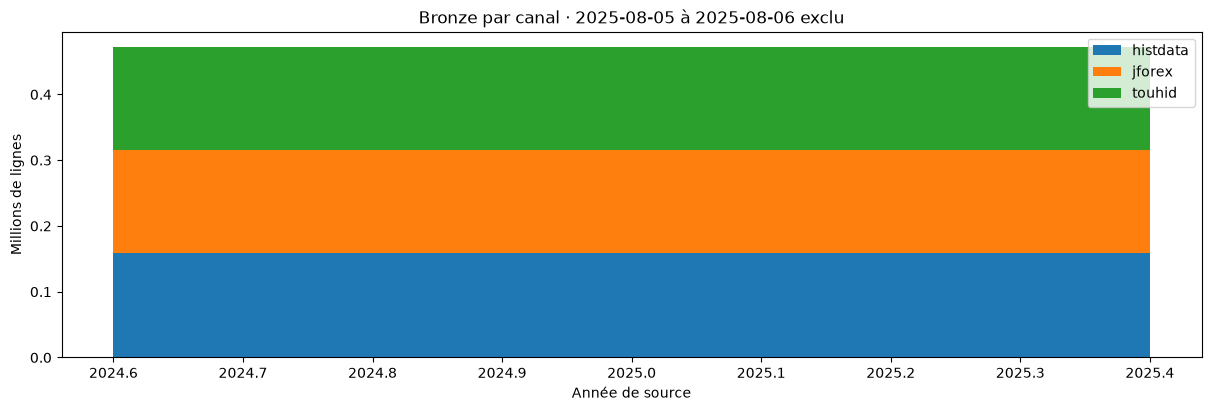

Les canaux utilisent leur horloge source. Les volumes empilés incluent les recouvrements.


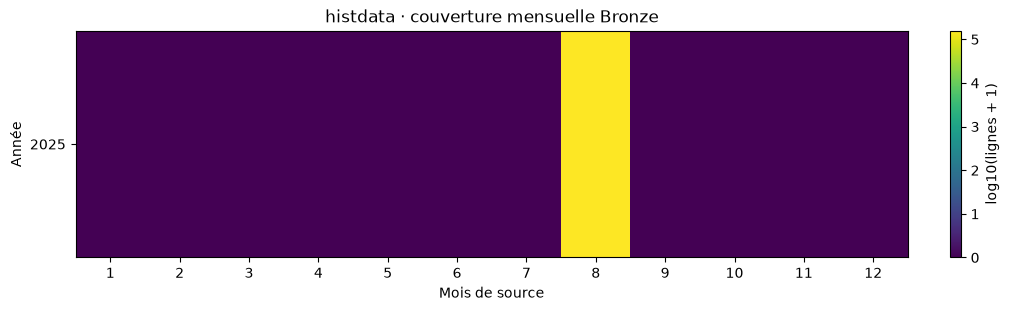

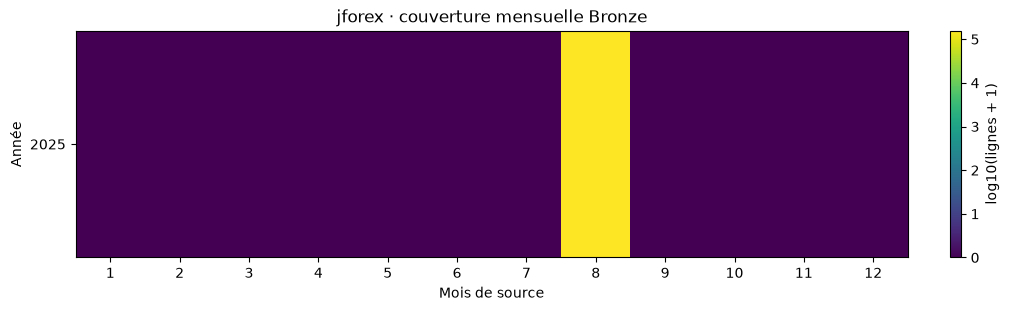

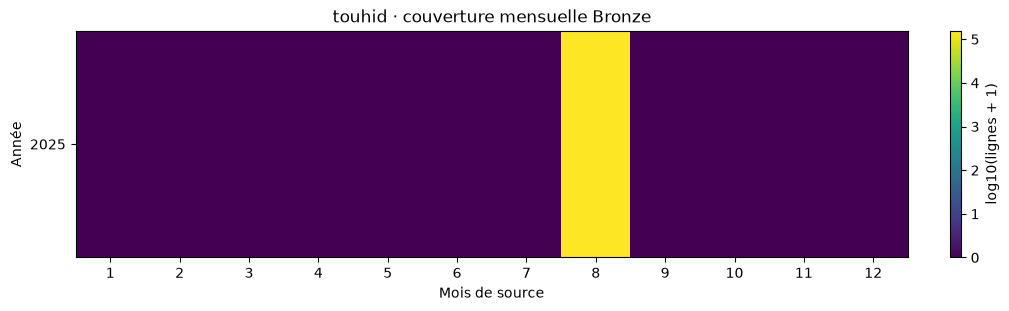

Partitions non vides 3 min 156842 moyenne 157272.33333333334 médiane 156842 max 158133 écart-type 608.5832363412219 max/médiane 1.0082312135779956


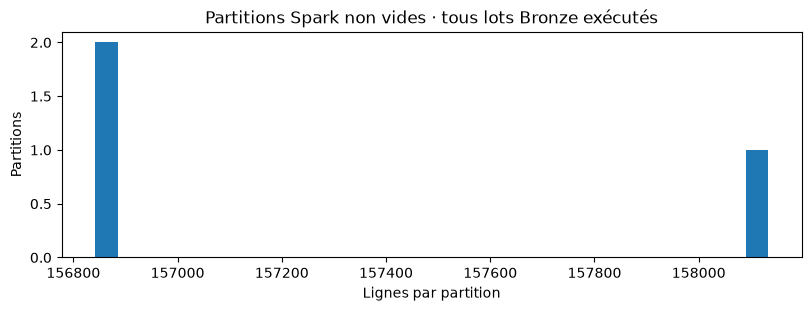

In [6]:
def bronze_charts():
    import matplotlib.pyplot as plt
    import statistics
    yearly=defaultdict(lambda:defaultdict(int))
    monthly=defaultdict(lambda:defaultdict(int))
    sizes=[]
    for a,_ in monthly_windows(start,end):
        state=manifest(f'bronze_{a}')
        if state.get('run_key') != run_key:
            continue
        sizes.extend(state['nonempty_partition_rows'])
        for record in state['sources']:
            key=record['source_id']
            yearly[key][a.year]+=record['ticks']
            monthly[key][(a.year,a.month)]+=record['ticks']
    if not yearly:
        print('Aucun profil Bronze compatible sauvegardé.')
        return
    years=sorted({year for rows in yearly.values() for year in rows})
    bottom=[0]*len(years)
    fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
    for source,counts in sorted(yearly.items()):
        values=[counts.get(year,0)/1e6 for year in years]
        ax.bar(years,values,bottom=bottom,label=source)
        bottom=[a+b for a,b in zip(bottom,values)]
    ax.set(title=f'Bronze par canal · {start} à {end} exclu',xlabel='Année de source',ylabel='Millions de lignes')
    ax.legend()
    display(fig)
    plt.close(fig)
    print('Les canaux utilisent leur horloge source. Les volumes empilés incluent les recouvrements.')
    for source,rows in sorted(monthly.items()):
        fig,ax=plt.subplots(figsize=(10,3),layout='constrained')
        image=ax.imshow([[math.log10(1+rows.get((year,month),0)) for month in range(1,13)] for year in years],aspect='auto')
        ax.set(title=f'{source} · couverture mensuelle Bronze',xlabel='Mois de source',ylabel='Année',
               xticks=range(12),xticklabels=range(1,13),yticks=range(len(years)),yticklabels=years)
        fig.colorbar(image,label='log10(lignes + 1)')
        display(fig)
        plt.close(fig)
    if sizes:
        med=statistics.median(sizes)
        print('Partitions non vides',len(sizes),'min',min(sizes),'moyenne',statistics.mean(sizes),
              'médiane',med,'max',max(sizes),'écart-type',statistics.pstdev(sizes),'max/médiane',max(sizes)/med)
        fig,ax=plt.subplots(figsize=(8,3),layout='constrained')
        ax.hist(sizes,bins=30)
        ax.set(title='Partitions Spark non vides · tous lots Bronze exécutés',xlabel='Lignes par partition',ylabel='Partitions')
        display(fig)
        plt.close(fig)
bronze_charts()

## Contrôles et bilan

Les tests portent sur l’unicité des chemins, les bornes et la conservation des effectifs publiés.

In [7]:
assert len({row['source_file_id'] for row in sources})==len(sources)
assert all(row['first'][:10]<=row['last'][:10] for row in sources)
if active('03'):
    summary=manifest('bronze')
    assert sum(summary['source_counts'].values())==summary['rows']
    finish('tests_bronze',passed=['inventory_unique','dates_ordered','row_balance'])
stage_report()

**tests_bronze** · complete.

{'status': 'complete', 'elapsed_run_seconds': 113.366, 'passed': ['inventory_unique', 'dates_ordered', 'row_balance']}
Métriques Spark UI {'stages': 49, 'numTasks': 160, 'numFailedTasks': 0, 'executorCpuTime': 93805815700, 'jvmGcTime': 1906, 'shuffleReadBytes': 28609161, 'shuffleWriteBytes': 28609161, 'diskBytesSpilled': 0, 'memoryBytesSpilled': 0}
bronze {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 106.096, 'chunks': 1, 'rows': 471817, 'source_counts': {'histdata': 158133, 'jforex': 156842, 'touhid': 156842}}
